# Estudo de Caso MegaTelco - Classificador Naive Bayes

## Disciplina: Inteligência Artificial e Aplicações - IIA007
## FATEC Ferraz de Vasconcelos
### Professora: Ana Rosa C. Tonão               
#### Data: 16/11/2026  
#### Alunas: Gabriele Monteiro, Tainá Kasai e Talita Sabine

---------

## **Descrição dos Dados**


Para este projeto, a MegaTelCo forneceu um conjunto de dados históricos de 14.088 clientes, a partir dos quais já criou dois conjuntos de dados: um conjunto de treino (dataset - churn_hw2_train.xlsx) com 9.856 clientes e um conjunto de teste (dataset - churn_hw2_test.xlsx) com 4.232 clientes.

No momento da coleta dos dados, cada cliente tinha permanecido na empresa ou tinha saído (churned).

Cada cliente é descrito pelas variáveis listadas abaixo:


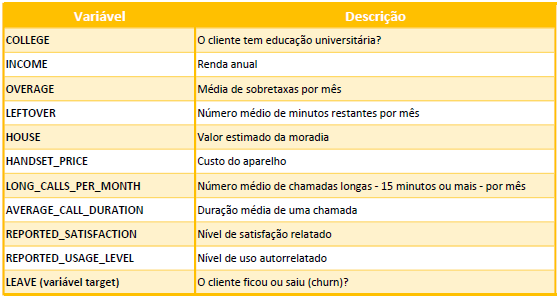

**Fonte**:

FAWCETT,T.;PROVOST,F. **Data Science para Negócios**.Rio de Janeiro, RJ:Alta Books, 2016.
    


## *Preparando o ambiente*

In [2]:
import os
os.getcwd()


'c:\\Users\\casa\\Desktop\\IIA007'

In [3]:
os.chdir(r'C:\Users\casa\Desktop\IIA007')
os.getcwd()


'c:\\Users\\casa\\Desktop\\IIA007'

## *Importando as bibliotecas necessárias*


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


-----
## **(1) Carregando o conjunto de dados**
-----

### *Carregando os dados de TREINO:*

In [6]:
# Carregando um arquivo de texto separado por ponto e vírgula (.csv)

retention_train = pd.read_csv('retention_train_full_tratado.csv')

### *Carregando os dados de TESTE:*

In [7]:
# Carregando um arquivo de texto separado por ponto e vírgula (.csv)

retention_test = pd.read_csv('retention_test_full_tratado.csv')

### *Unificando TREINO e TESTE:*

In [8]:
retention_unificado = pd.concat([retention_train, retention_test], ignore_index=True)

In [9]:
retention_unificado.info()

<class 'pandas.DataFrame'>
RangeIndex: 14083 entries, 0 to 14082
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Unnamed: 0                      14083 non-null  int64  
 1   college                         14083 non-null  int64  
 2   income                          14083 non-null  float64
 3   leftover                        14083 non-null  float64
 4   house                           14083 non-null  float64
 5   handset_price                   14083 non-null  float64
 6   over_15mins_calls_per_month     14083 non-null  float64
 7   average_call_duration           14083 non-null  float64
 8   reported_satisfaction           14078 non-null  str    
 9   reported_usage_level            14079 non-null  str    
 10  considering_change_of_plan      14082 non-null  str    
 11  leave                           14083 non-null  int64  
 12  reported_satisfaction_num       14078 non-n

In [10]:
# Inspecionando o dataframe de TREINO

print("Linhas, colunas: ",retention_unificado.shape, "\n")

print("Nomes de colunas: ",retention_unificado.columns, "\n")

print("Índices: ",retention_unificado.index, "\n")

Linhas, colunas:  (14083, 16) 

Nomes de colunas:  Index(['Unnamed: 0', 'college', 'income', 'leftover', 'house', 'handset_price',
       'over_15mins_calls_per_month', 'average_call_duration',
       'reported_satisfaction', 'reported_usage_level',
       'considering_change_of_plan', 'leave', 'reported_satisfaction_num',
       'reported_usage_level_num', 'considering_change_of_plan_num',
       'is_outlier'],
      dtype='str') 

Índices:  RangeIndex(start=0, stop=14083, step=1) 



In [11]:
# Preparando os dados 
X = retention_unificado[['income', 'house' ,'handset_price',  'leftover' , 'over_15mins_calls_per_month' , 'average_call_duration']]
Y = retention_unificado['leave']

-----
## **(3) Criando e treinando o classificador**
-----

In [12]:
# Criando o classificador Naive Bayes Gaussiano
modelo_nb = GaussianNB()


-----
## **(4) Realizar a previsão dos clientes que podem deixar a empresa**
-----

### *Aplicando seu modelo aos dados de teste*

In [13]:
# Aplicando o modelo com Cross-Validation (10 folds)
pred_labels = cross_val_predict(modelo_nb, X, Y, cv=10)
true_labels = Y


-----
## **(5) Avaliando a qualidade do seu modelo**
-----

### *Criando a matriz de confusão*

In [14]:
# Create confusion matrix
# Acurácia média com Cross-Validation (10 folds)
scores = cross_val_score(modelo_nb, X, Y, cv=10, scoring='accuracy')
print(f"Acurácia média (CV=10): {scores.mean():.4f} (+/- {scores.std():.4f})\n")

# Matriz de Confusão
cm = confusion_matrix(true_labels, pred_labels)
print("Matriz de Confusão:\n", cm)



Acurácia média (CV=10): 0.7259 (+/- 0.0072)

Matriz de Confusão:
 [[9287  859]
 [3001  936]]


### *Gerando o classification report*

In [15]:
# Classification report
targets = ['Class-0', 'Class-1']
print('\n', classification_report(true_labels, pred_labels, target_names=targets))


               precision    recall  f1-score   support

     Class-0       0.76      0.92      0.83     10146
     Class-1       0.52      0.24      0.33      3937

    accuracy                           0.73     14083
   macro avg       0.64      0.58      0.58     14083
weighted avg       0.69      0.73      0.69     14083



-----
# **CONCLUSÃO**
-----

### **Análise das Métricas – Classificador Naive Bayes Gaussiano (Validação Cruzada com 10 Folds)**

Com a aplicação da validação cruzada (*10-fold cross-validation*) na base unificada composta por **14.083 clientes**, o modelo Naive Bayes Gaussiano obteve os seguintes indicadores na previsão de cancelamento (*churn*):

* **Acurácia Global (72,59% / 0,73):** O classificador acertou 10.223 do total de 14.083 registros avaliados (9.287 verdadeiros negativos e 936 verdadeiros positivos). Assim como observado em bases desbalanceadas, essa taxa geral é sustentada sobretudo pelo acerto na classe majoritária (**Class-0** — clientes que permaneceram, com *recall* de **92%** e precisão de **76%**).
* **Precisão na Classe de Evasão – Class-1 (52% / 0,52):** Dos **1.795 clientes** apontados pelo modelo como em risco de saída (936 verdadeiros positivos e 859 falsos positivos), 52% realmente encerraram o contrato. Isso significa que quase metade dos alertas emitidos corresponde a falsos positivos, o que acarretaria custos adicionais com ofertas de retenção para clientes sem intenção real de evasão.
* **Recall / Sensibilidade – Class-1 (24% / 0,24):** Entre os **3.937 clientes** que de fato abandonaram a operadora, o algoritmo identificou **936** corretamente e deixou de sinalizar **3.001** (76% de falsos negativos). Embora apresente sensibilidade superior à da Regressão Logística neste conjunto de atributos, o índice ainda é insuficiente para cobrir a maior parte das perdas reais de clientes.

**Considerações Finais:** O modelo Naive Bayes Gaussiano alcançou acurácia global de 72,59% e *F1-score* de 0,33 para a classe de evasão (*Class-1*), revelando-se ligeiramente mais sensível na detecção de *churn* (24%) do que a Regressão Logística, porém com maior incidência de falsos positivos (precisão de 52%). A premissa de independência condicional entre as variáveis numéricas limita o poder discriminativo do algoritmo, indicando que o tratamento de desbalanceamento e a inclusão de atributos categóricos (como nível de satisfação e intenção de troca de plano) são passos essenciais para aprimorar o modelo.

# ***FIM***